# Linear Regression

## Introduction

Given an input feature matrix $\mathbf{X}$, the linear regression model predicts a real-valued output $\mathbf{Y}$. For each observation $i = 1, 2, \dots, N$, the predicted output,

$$
\hat y_i = \beta_0 + \sum_{j=1}^{p} x_{ij}\beta_j 
$$

where the $\beta_j$'s are unknown parameters (coefficients) of the model. The model is linear in terms of these parameters (Note these parameters are just the estimates).

Additionally, we incorporate the intercept term $\beta_0$ into the model by augmenting $\mathbf{X}$ with an extra column of ones as its first column.

In Matrix Form 
$$
\mathbf{Y}_{(N \times 1)} = \mathbf{X}_{(N \times (p+1))} \; \boldsymbol{\beta}_{((p+1) \times 1)}
$$

Here we expand these matrix to explicity show its structure,

$$
\mathbf{X}_{(N \times (p+1))} =
\begin{bmatrix}
1 & x_{11} & x_{12} & \cdots & x_{1p} \\
1 & x_{21} & x_{22} & \cdots & x_{2p} \\
\vdots & \vdots & \vdots & \cdots & \vdots \\
1 & x_{N1} & x_{N2} & \cdots & x_{Np}
\end{bmatrix}
$$

$$
\boldsymbol{\beta}_{((p+1) \times 1)} =
\begin{bmatrix}
\beta_0 \\
\beta_1 \\
\vdots \\
\beta_p
\end{bmatrix}
$$

$$
\mathbf{Y}_{(N \times 1)} =
\begin{bmatrix}
y_1 \\
y_2 \\
\vdots \\
y_N
\end{bmatrix}
$$

Dimensionality check: $ (N \times 1) = (N \times (p+1)) \cdot ((p+1) \times 1) $

Typically we have a set of training data from which we estimate the parameters $\beta$. Each $x_{i} = (x_{i1},x_{i2},...,x_{ip},)^{T}$ is a vector of feature measurements for ith case. The most popular estimation method is $\textbf{ ordinary least squares (OLS)}$, in which we pick the coefficient to minimize the $\textit{residual sum of squares}$.
$$
\text{RSS} = \sum_{i=1}^{N} (y_i - \hat{y}_i)^2
$$

$$
\text{RSS} = \sum_{i=1}^{N} (y_i - \beta_0 - \sum_{j=1}^{p} x_{ij} \beta_j  )^2
$$
Note: Most of the time, when people say "linear regression", they implicitly mean OLS, but technically they are different. Linear regression is model while OLS is one of the methods to estimate parameters. 

Since RSS is quadratic in $\beta$, it has the shape of a higher-dimensional parabola (bowl-shaped surface).

The second derivative (Hessian) is
$$
\nabla^2_{\beta} \, RSS = 2 X^T X.
$$

Assume(for the moment) that $X$ has full column rank, and hence $X^T X$ is always $\geq 0$ (positive definite), then RSS is convex.
Therefore, a global minimum always exists. If $X^T X$ is positive definite, then the minimum is unique. Otherwise, if it is only positive semidefinite, the surface is flat in some directions (like a flat bowl), and the solution is not unique. It might happen that columns of X are not linearly independent (e.g., $x_2 = 3\,x_1$), then the parameters are not uniquely defined.
## Minimizing RSS (Analytical Solution)

We want to minimize the Residual Sum of Squares (RSS):

$$
RSS = (\mathbf{Y} - \mathbf{X}\beta)^T (\mathbf{Y} - \mathbf{X}\beta)
$$

Expanding the above expression:

$$
RSS = \mathbf{Y}^T \mathbf{Y}
- \mathbf{Y}^T \mathbf{X}\beta
- (\mathbf{X}\beta)^T \mathbf{Y}
+ (\mathbf{X}\beta)^T (\mathbf{X}\beta)
$$

Using $(\mathbf{X}\beta)^T = \beta^T \mathbf{X}^T$:

$$
RSS = \mathbf{Y}^T \mathbf{Y}
- \mathbf{Y}^T \mathbf{X}\beta
- \beta^T \mathbf{X}^T \mathbf{Y}
+ \beta^T \mathbf{X}^T \mathbf{X} \beta
$$

Since $\mathbf{Y}^T \mathbf{X}\beta$ is a scalar (for which $s = s^T$):

$$
\mathbf{Y}^T \mathbf{X}\beta = \beta^T \mathbf{X}^T \mathbf{Y}
$$

So,

$$
RSS = \mathbf{Y}^T \mathbf{Y}
- 2 \beta^T \mathbf{X}^T \mathbf{Y}
+ \beta^T \mathbf{X}^T \mathbf{X} \beta
$$

Taking derivative w.r.t. $\beta$:

$$
\frac{\partial RSS}{\partial \beta}
= -2 \mathbf{X}^T \mathbf{Y}
+ 2 \mathbf{X}^T \mathbf{X} \beta
$$

Setting the derivative to zero we obtain the unique solution:

$$
-2 \mathbf{X}^T \mathbf{Y}
+ 2 \mathbf{X}^T \mathbf{X} \beta = 0
$$


$$
\mathbf{X}^T \mathbf{X} \beta = \mathbf{X}^T \mathbf{Y}
$$

This is called the Normal Equation.

If $\mathbf{X}^T \mathbf{X}$ is invertible:

$$
\beta = (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{Y}
$$
The predictions are then given as:
$$
\mathbf{\hat Y} = \mathbf{X \beta} = \mathbf{X} (\mathbf{X}^T \mathbf{X})^{-1} \mathbf{X}^T \mathbf{Y}
$$

The derivation above provides an analytical (closed-form) solution to the least squares problem, where the optimal coefficients are obtained directly using a single formula. 

In practice, however, numerical methods such as QR decomposition are preferred for solving linear regression problems. QR decomposition is widely used in scientific computing libraries (e.g., in Python) because it avoids explicitly computing the inverse of $X^T X$, which can be computationally expensive and numerically unstable. Instead, it reformulates the problem into a more stable system that can be solved efficiently. It is important to note that QR decomposition does not resolve issues arising from linear dependence among the columns of $X$. In such cases, the system does not have a unique solution, and multiple solutions exist, just as in the case of the normal equation.

## QR Decomposition using Gram-Schmidt process:

We want to decompose the matrix $X$ as:

$$
X = QR
$$

where:
- $Q$ has orthonormal columns ($Q^T Q = I$)
- $R$ is an upper triangular matrix

---

### Step 1: Write columns of $X$

Let the columns of $X$ be:

$$
X = [x_1 \; x_2 \; \dots \; x_p]
$$

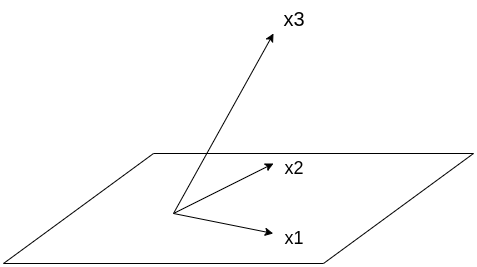

---

### Step 2: Construct orthonormal vectors

We build $Q = [q_1 \; q_2 \; \dots \; q_p]$

#### First vector: Just points along $x_1$,

$$
q_1 = \frac{x_1}{\|x_1\|}
$$
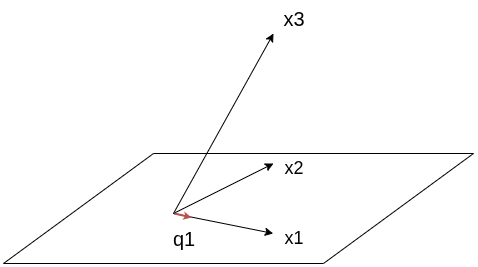
---

#### Second vector:

Remove projection of $x_2$ onto $q_1$:

$$
u_2 = x_2 - (q_1^T x_2) q_1
$$

Normalize:

$$
q_2 = \frac{u_2}{\|u_2\|}
$$
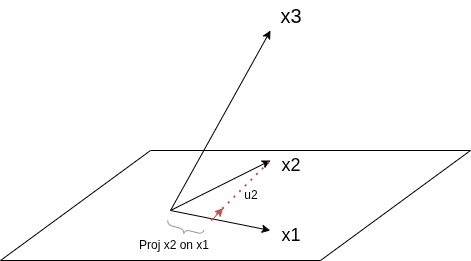


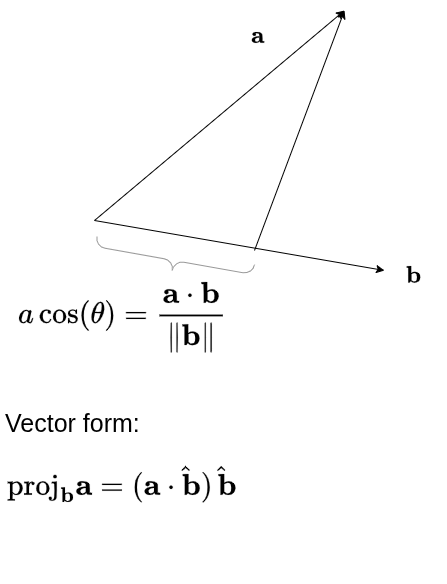
---
#### Third vector:

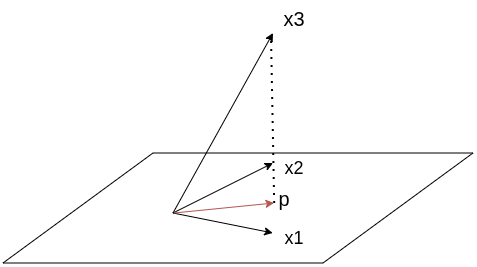

We project $x_3$ onto the subspace spanned by $q_1$ and $q_2$. Since $q_1$ and $q_2$ form an orthonormal set in this subspace, any vector in the subspace can be expressed as their linear combination. Thus, the projection can be written as

$$
p = a\,q_1 + b\,q_2
$$

Now we define
$$
u_3 = x_3 - p = x_3 - (a\,q_1 + b\,q_2)
$$

Since $u_3$ is orthogonal to both $q_1$ and $q_2$, we impose:
$$
u_3 \cdot q_1 = 0 \quad \text{and} \quad u_3 \cdot q_2 = 0
$$

Substituting $u_3$:

$$
(x_3 - a\,q_1 - b\,q_2)\cdot q_1 = 0
$$

$$
(x_3 - a\,q_1 - b\,q_2)\cdot q_2 = 0
$$

Using orthonormality ($q_i \cdot q_j = 0$ for $i \neq j$, and $q_i \cdot q_i = 1$), we get:

$$
a = x_3 \cdot q_1, \qquad b = x_3 \cdot q_2
$$

Hence, the projection becomes:

$$
p = (x_3 \cdot q_1)q_1 + (x_3 \cdot q_2)q_2
$$

and therefore,

$$
u_3 = x_3 - (x_3 \cdot q_1)q_1 - (x_3 \cdot q_2)q_2
$$

Finally, normalize to obtain:
$$
q_3 = \frac{u_3}{\|u_3\|}
$$
#### General step:

For $j = 1, 2, \dots, p$:

$$
u_j = x_j - \sum_{i=1}^{j-1} (q_i^T x_j) q_i
$$

$$
q_j = \frac{u_j}{\|u_j\|}
$$

---

### Step 3: Form matrix $Q$

$$
Q = [q_1 \; q_2 \; \dots \; q_p]
$$

---

### Step 4: Construct $R$

Entries of $R$ are:

$$
R_{ij} =
\begin{cases}
q_i^T x_j & i \le j \\
0 & i > j
\end{cases}
$$

---

### Step 5: Final decomposition
$$
\mathbf{X}_{\,n \times p} = \mathbf{Q}_{\,n \times p}\,\mathbf{R}_{\,p \times p}
$$
---
### Step 6: Estimation of Parameters

We start with the linear model:
$$
\mathbf{\hat Y} = \mathbf{X}\,\mathbf{\beta}
$$

Using QR decomposition, $\mathbf{X} = \mathbf{Q}\mathbf{R}$:
$$
\mathbf{\hat Y} = \mathbf{Q}\,\mathbf{R}\,\mathbf{\beta}
$$

Multiply both sides by $\mathbf{Q}^T$:
$$
\mathbf{Q}^T \mathbf{\hat Y} = \mathbf{R}\,\mathbf{\beta}
$$

Define:
$$
\mathbf{z} = \mathbf{Q}^T \mathbf{Y}
$$

Thus:
$$
\mathbf{R}\,\mathbf{\beta} = \mathbf{z}
$$

Since $\mathbf{R}$ is upper triangular:

$$
R_{11}\beta_1 + R_{12}\beta_2 + \cdots + R_{1p}\beta_p = z_1
$$

$$
R_{22}\beta_2 + \cdots + R_{2p}\beta_p = z_2
$$

$$
\vdots
$$

$$
R_{pp}\beta_p = z_p
$$

---

### Back Substitution

Start from the last equation:

$$
\beta_p = \frac{z_p}{R_{pp}}
$$

Now substitute into the previous equation:

$$
R_{p-1,p-1}\beta_{p-1} + R_{p-1,p}\beta_p = z_{p-1}
$$

$$
\beta_{p-1} = \frac{z_{p-1} - R_{p-1,p}\beta_p}{R_{p-1,p-1}}
$$

Next step:

$$
\beta_{p-2} = \frac{z_{p-2} - R_{p-2,p-1}\beta_{p-1} - R_{p-2,p}\beta_p}{R_{p-2,p-2}}
$$

---

### General Form

$$
\beta_i = \frac{1}{R_{ii}} \left( z_i - \sum_{j=i+1}^{p} R_{ij}\beta_j \right), \quad i = p, p-1, \dots, 1
$$
## A beautifully elegant solution — no inverses, just simple linear algebra. 

# Implementation

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

In [2]:
#FIT BOSTON DATA
Boston = pd.read_csv('data/Boston.csv')
Boston[:5]

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [3]:
import numpy as np

def qr_gram_schmidth(X):
    n, p = X.shape  # n: rows, p: columns
    
    Q = np.zeros((n, p))
    R = np.zeros((p, p))
    
    for i in range(p):
        Q[:, i] = X[:, i]   # take i-th column
        
        for j in range(i):
            R[j, i] = np.dot(Q[:, j], X[:, i])
            Q[:, i] -= R[j, i] * Q[:, j]
        
        R[i,i] = np.linalg.norm(Q[:,i])
        Q[:, i] /= np.linalg.norm(Q[:,i])
    return Q, R

In [4]:
#Test QR Decomposition
X = np.random.randn(3,3)
Q, R = qr_gram_schmidth(X)
Q_np, R_np = np.linalg.qr(X)
print(Q)
print(Q_np)

[[ 0.67455096 -0.68912092  0.2647515 ]
 [ 0.72553532  0.55263516 -0.41011326]
 [ 0.13630664  0.46872885  0.87276214]]
[[-0.67455096  0.68912092  0.2647515 ]
 [-0.72553532 -0.55263516 -0.41011326]
 [-0.13630664 -0.46872885  0.87276214]]


In [5]:
def solve_qr(X, Y):
    Q, R = qr_gram_schmidth(X)
    
    Z = Q.T @ Y   # Q^T Y
    
    p = R.shape[0]
    Beta = np.zeros(p)
    
    # Backward substitution
    for i in reversed(range(p)):
        Beta[i] = Z[i]
        
        for j in range(i+1, p):
            Beta[i] -= R[i, j] * Beta[j]
        
        Beta[i] /= R[i, i]
    
    return Beta

In [6]:
x = Boston['lstat'].values
y = Boston['medv'].values

n = len(x)

# Design matrix with intercept
X = np.column_stack((np.ones(n), x))

Beta = solve_qr(X, y)

print("Beta:", Beta)

Beta: [34.55384088 -0.95004935]


# Gradient Descent (Iterative Method)

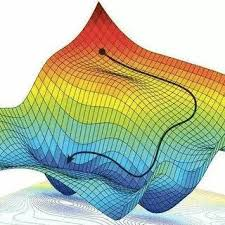

# The idea:
Imagine being on a foggy mountain trying to reach the bottom. Since visibility is low, you cannot see the full path and must rely only on local information. At each step, you measure the slope and move in the direction of steepest descent (downhill). Repeating this process eventually leads you toward a minimum, though you may get stuck in a local minimum or saddle point.

## Gradient Descent for Linear Regression

We define the Residual Sum of Squares (RSS):

$$
RSS(\boldsymbol{\beta}) = \sum_{i=1}^{N} (y_i - \hat{y}_i)^2
$$

In matrix form:

$$
RSS(\boldsymbol{\beta}) = (\mathbf{Y} - \mathbf{X \beta})^T (\mathbf{Y} - \mathbf{X \beta})
$$

The gradient is

$$
\frac{\partial RSS}{\partial \beta}
= -2 \mathbf{X}^T \mathbf{Y}
+ 2 \mathbf{X}^T \mathbf{X} \beta
$$

$$
\frac{\partial RSS}{\partial \beta}
= -2 \mathbf{X}^T (\mathbf{Y} -\mathbf{X} \beta)
$$

Next we update the parameters,

$$
\boldsymbol{\beta}^{(t+1)} = \boldsymbol{\beta}^{(t)} - \alpha \, \frac{\partial RSS}{\partial \beta}
$$

Substituting the gradient:

$$
\boldsymbol{\beta}^{(t+1)} = \boldsymbol{\beta}^{(t)} + 2\alpha \mathbf{X}^T (\mathbf{Y} - \mathbf{X \beta})
$$

One can absorb 2 inside $\alpha$,
$$
\boldsymbol{\beta}^{(t+1)} = \boldsymbol{\beta}^{(t)} + \alpha \mathbf{X}^T (\mathbf{Y} - \mathbf{X \beta})
$$



# Implementation

In [7]:
#FIT BOSTON DATA
Boston = pd.read_csv('data/Boston.csv')
Boston[:5]

,Unnamed: 0,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,lstat,medv
0,1,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,4.98,24.0
1,2,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,9.14,21.6
2,3,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,4.03,34.7
3,4,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,2.94,33.4
4,5,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,5.33,36.2


In [8]:
x = Boston['lstat'].to_numpy()
y = Boston['medv'].to_numpy()

iiter = 100000
lrate = 0.001

par = [0, 0]

for ij in range(iiter):
        ypred = par[0] + (par[1] * x)
        error = y - ypred
        par[0] += 2 * lrate * np.mean(error)
        par[1] += 2 * lrate * np.mean(error * x)

print(par)


[np.float64(34.553840879375734), np.float64(-0.9500493537575491)]


# Another Example

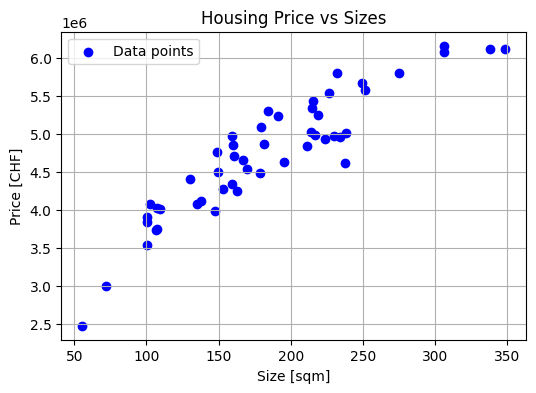

In [11]:


import numpy as np
from utils_linear_regression import load_house_data, plot_housing_prices, plot_loss_landscape, animate_gradient_descent

from IPython.display import HTML

# load the housing price data
sizes, prices, labels = load_house_data('data/housing_price_labelled.txt')

# plot the data
plot_housing_prices(sizes,prices,scaled=False)


# Feature Scaling through Standardization

Many machine learning algorithms perform much better when the input features have similar numerical ranges.  
A common technique is **standardization**, where each feature is transformed as

$$
z = \frac{x - \mu}{\sigma}
$$

where:

- $\mu$ is the mean of the feature
- $\sigma$ is the standard deviation

After standardization:

- the feature mean becomes approximately $0$
- the standard deviation becomes approximately $1$


Real-world datasets often contain features with very different magnitudes and units. Without scaling, features with larger numerical values can dominate the learning process resulting in loss surface which is stretched or elongated along one direction, resulting in oscillations and slow convergence.


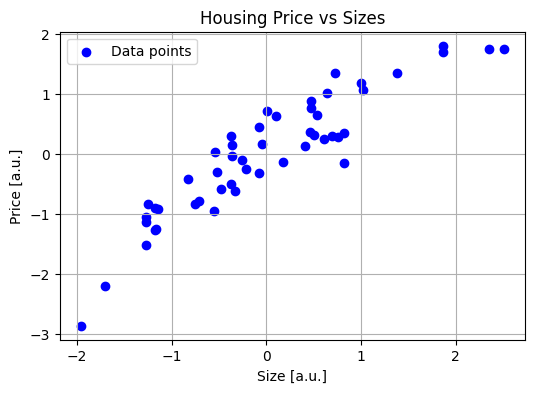

In [12]:
# Scale the features such that they are centered around zero and have standard deviation of one, z = x - u /sigma
x = (sizes - np.mean(sizes)) / np.std(sizes)
y = (prices - np.mean(prices)) / np.std(prices)

# plot the scaled data
plot_housing_prices(x,y,scaled=True)


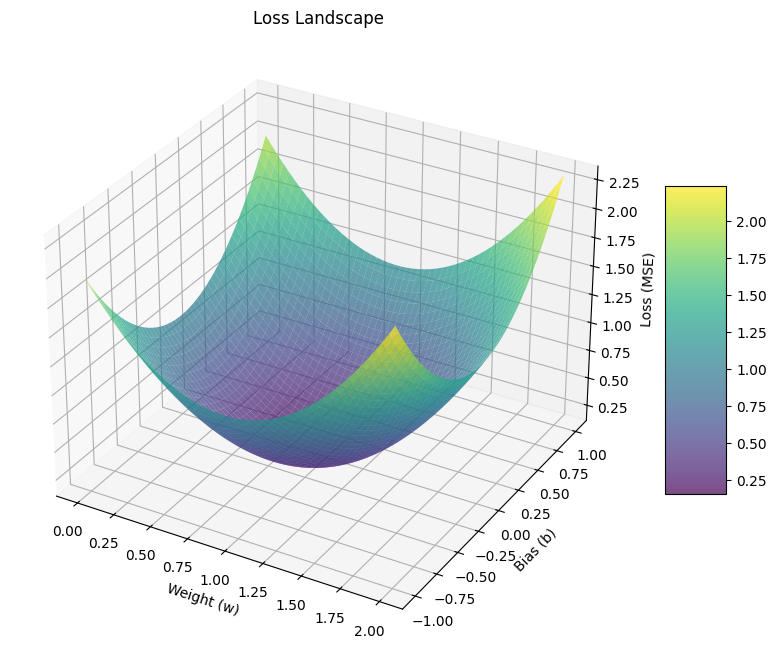

In [13]:
# Calculate loss (Mean Squared Error) for each combination of w and b
def calculate_loss(w, b, x_data, y_data):
    y_pred = w * x_data + b
    loss = np.mean((y_pred - y_data) * (y_pred-y_data))
    return loss

# Create ranges for w nad b to plot loss surface
w_range = np.linspace(0,2,50)
b_range = np.linspace(-1,1,50)

W, B = np.meshgrid(w_range, b_range)
Loss = np.zeros_like(W)

# calculate loss
for i in range (W.shape[0]):
    for j in range (W.shape[1]):
        Loss[i,j] = calculate_loss(W[i,j], B[i,j],x, y)

# plot the loss surface 
plot_loss_landscape(W, B, Loss)

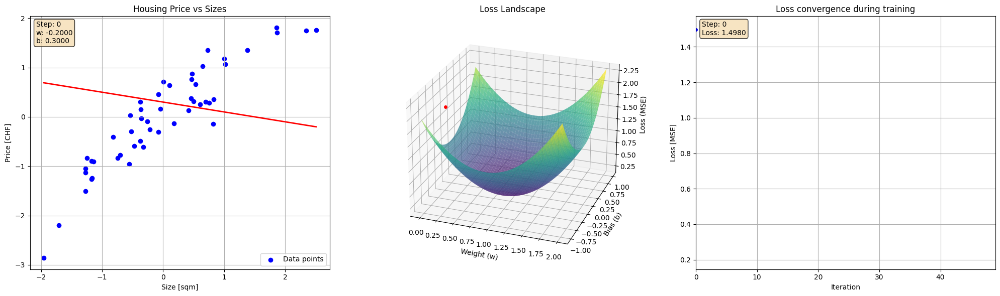

In [14]:
# This may take a minute or more..
# Perform gradient descent
def gradient_descent_path(x_data,y_data,learning_rate = 0.05, n_iterations=20):

    # Initialise parameters
    w = -0.2
    b = 0.3

    # Store path (Using list since can be appended)
    w_path = [w]
    b_path = [b]
    loss_path = [calculate_loss(w,b,x_data, y_data)]
    
    for i in range(n_iterations - 1): # initial values are 0th iteration
        # calculate predictions
        y_pred = w * x_data + b

        # calculate gradients:
        dw = 2 * np.mean((y_pred - y_data) * x_data)
        db = 2 * np.mean(y_pred - y_data)

        # Update parameters
        w -= learning_rate * dw
        b -= learning_rate * db

        w_path.append(w)
        b_path.append(b)
        loss_path.append(calculate_loss(w, b, x_data, y_data))

    return np.array(w_path), np.array(b_path), np.array(loss_path) # convert to array

w_path, b_path, loss_path = gradient_descent_path(x,y, learning_rate=0.1, n_iterations=50)

#for i, loss in enumerate(loss_path):
    #print(f"loss_path[{i}] = {loss}")



anim = animate_gradient_descent(W, B, Loss, x, y, w_path, b_path, loss_path)
save_path="gradient-descent-animation.gif"
anim.save(save_path)
HTML(anim.to_jshtml())
